# PathSnap — 04 · Bayesian Hyperparameter Optimisation (HistGradientBoosting)

Searches are run by `scripts/tune_hgb.py` (stage 1, then `--stage2`); all trials are stored in `outputs/models/tuning/optuna.db`.

| Item | Choice |
|---|---|
| Model | HistGradientBoostingClassifier (selected in notebook 03, section 6) |
| Strategy | Bayesian optimisation with **TPE** (Tree-structured Parzen Estimator, Optuna), seed 42 |
| Objective | **maximise mean 5-fold GroupKFold Top-1 accuracy** on the 78 reliable train trips. Same folds and scoring protocol as stage 4 |
| Stage 1 | Wide search space; trial 0 = the untuned stage-4 configuration; 10 random start-up trials, then TPE |
| Stage 2 | Refined search: `max_iter` widened (300–2000) because stage-1 best trials sat at its 800 ceiling; other ranges narrowed around the stage-1 top trials; seeded with the stage-1 top 3 |
| Pruning | MedianPruner: a trial is stopped after a fold if its running mean is below the median of earlier trials |
| Data rule | student_test is used once, after the search. The evaluator partition is never used |

In [1]:
import os, sys, json, time, warnings
sys.path.insert(0, os.path.abspath('..')); sys.path.insert(0, os.path.abspath('../scripts')); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, optuna
from collections import Counter
from sklearn.model_selection import GroupKFold
from src.features import FEATURES
from src.evaluation import all_metrics
from train_compare import load_train, N_FOLDS
from tune_hgb import make_model, SPACE, SPACE2
optuna.logging.set_verbosity(optuna.logging.WARNING)
TUN = '../outputs/models/tuning'; CMP = '../outputs/models/compare'; FIG = f'{TUN}/figures'; os.makedirs(FIG, exist_ok=True)
sns.set_theme(style='whitegrid'); pd.set_option('display.width', 220)
def savefig(name):
    plt.tight_layout(); plt.savefig(f'{FIG}/{name}.png', dpi=150, bbox_inches='tight'); plt.show()
DB = f'sqlite:///{TUN}/optuna.db'
s1 = optuna.load_study(study_name='hgb_top1', storage=DB); s2 = optuna.load_study(study_name='hgb_top1_stage2', storage=DB)
res = json.load(open(f'{TUN}/tuning_result_stage2.json'))
space = pd.DataFrame({'stage 1': {k: f'{v[0]} [{v[1]}, {v[2]}]' for k, v in SPACE.items()},
                      'stage 2': {k: f'{v[0]} [{v[1]}, {v[2]}]' for k, v in SPACE2.items()},
                      'why': {k: v[3] for k, v in SPACE.items()}})
space

,stage 1,stage 2,why
learning_rate,"log-uniform [0.01, 0.3]","log-uniform [0.01, 0.15]",step size; untuned 0.1 showed loss spikes
max_iter,"int, step 50 [100, 800]","int, step 100 [300, 2000]","number of boosting rounds (early stopping off,..."
max_leaf_nodes,"log-int [15, 255]","log-int [31, 255]",tree complexity
min_samples_leaf,"log-int [10, 1000]","log-int [20, 300]",smoothing; data has 340k rows per fold
l2_regularization,"log-uniform [0.001, 30.0]","log-uniform [0.001, 3.0]","shrinks leaf values, which counters the oversh..."
max_features,"uniform [0.3, 1.0]","uniform [0.45, 0.9]",feature subsampling per split (decorrelates tr...


## 1. Search record

In [2]:
def frame(study, stage):
    rows = []
    for t in study.trials:
        rows.append(dict(stage=stage, trial=t.number, state=t.state.name, cv_top1=t.value,
                         cv_log_loss=t.user_attrs.get('cv_log_loss'), seconds=t.user_attrs.get('seconds'), **t.params))
    return pd.DataFrame(rows)
T = pd.concat([frame(s1, 1), frame(s2, 2)], ignore_index=True)
T.to_csv(f'{TUN}/all_trials.csv', index=False)
for st, g in T.groupby('stage'):
    print(f'stage {st}: {len(g)} trials {dict(Counter(g.state))}')
print(f"total trials: {len(T)}   stage-2 search time: {res['search_seconds'] / 60:.1f} min on {os.cpu_count()} CPU cores")
print(f"best CV Top-1 {res['best_cv_top1']:.4f} ± {res['best_cv_top1_std']:.4f}   CV log loss {res['best_cv_log_loss']:.4f}")
print('best parameters:', json.dumps(res['best_params'], indent=1))
T[T.state == 'COMPLETE'].sort_values('cv_top1', ascending=False).head(10).round(4)

stage 1: 30 trials {'COMPLETE': 19, 'PRUNED': 10, 'FAIL': 1}
stage 2: 19 trials {'COMPLETE': 7, 'PRUNED': 12}
total trials: 49   stage-2 search time: 30.6 min on 10 CPU cores
best CV Top-1 0.8609 ± 0.0431   CV log loss 0.0968
best parameters: {
 "learning_rate": 0.03370962431306001,
 "max_iter": 800,
 "max_leaf_nodes": 84,
 "min_samples_leaf": 65,
 "l2_regularization": 0.030550893424685692,
 "max_features": 0.6681237429283018
}


,stage,trial,state,cv_top1,cv_log_loss,seconds,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,l2_regularization,max_features
13,1,13,COMPLETE,0.8609,0.0968,101.4844,0.0337,800,84,65,0.0306,0.6681
30,2,0,COMPLETE,0.8609,0.0968,104.7879,0.0337,800,84,65,0.0306,0.6681
42,2,12,COMPLETE,0.8607,0.1014,136.0231,0.0366,900,161,60,0.0660,0.7950
31,2,1,COMPLETE,0.8606,0.0979,113.6173,0.0381,700,121,60,0.1256,0.6787
14,1,14,COMPLETE,0.8606,0.0979,114.0629,0.0381,700,121,60,0.1256,0.6787
16,1,16,COMPLETE,0.8606,0.0998,114.4711,0.0652,800,64,122,0.0079,0.7959
32,2,2,COMPLETE,0.8606,0.0998,96.6516,0.0652,800,64,122,0.0079,0.7959
15,1,15,COMPLETE,0.8605,0.0963,135.4522,0.0235,800,124,64,0.1898,0.6366
27,1,27,COMPLETE,0.8604,0.1028,129.6512,0.0599,750,151,39,0.5772,0.5908
18,1,18,COMPLETE,0.8603,0.1041,109.9253,0.0805,800,96,42,0.0272,0.6813


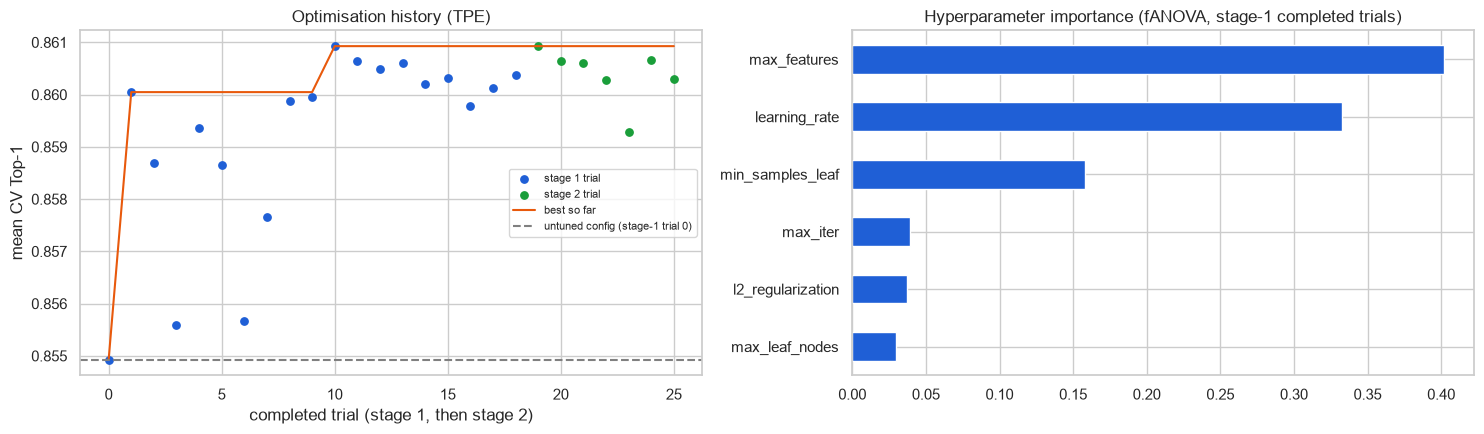

In [3]:
done = T[T.state == 'COMPLETE'].reset_index(drop=True)
done['order'] = np.arange(len(done))
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for st, c in [(1, '#1f5fd6'), (2, '#1a9e3a')]:
    d = done[done.stage == st]; ax[0].scatter(d.order, d.cv_top1, s=28, c=c, label=f'stage {st} trial')
ax[0].plot(done.order, done.cv_top1.cummax(), c='#e8590c', label='best so far')
ax[0].axhline(done.cv_top1.iloc[0], ls='--', c='grey', label='untuned config (stage-1 trial 0)')
ax[0].set_xlabel('completed trial (stage 1, then stage 2)'); ax[0].set_ylabel('mean CV Top-1'); ax[0].legend(fontsize=8)
ax[0].set_title('Optimisation history (TPE)')
imp = optuna.importance.get_param_importances(s1)
pd.Series(imp).sort_values().plot.barh(ax=ax[1], color='#1f5fd6')
ax[1].set_title('Hyperparameter importance (fANOVA, stage-1 completed trials)')
savefig('01_history_importance')

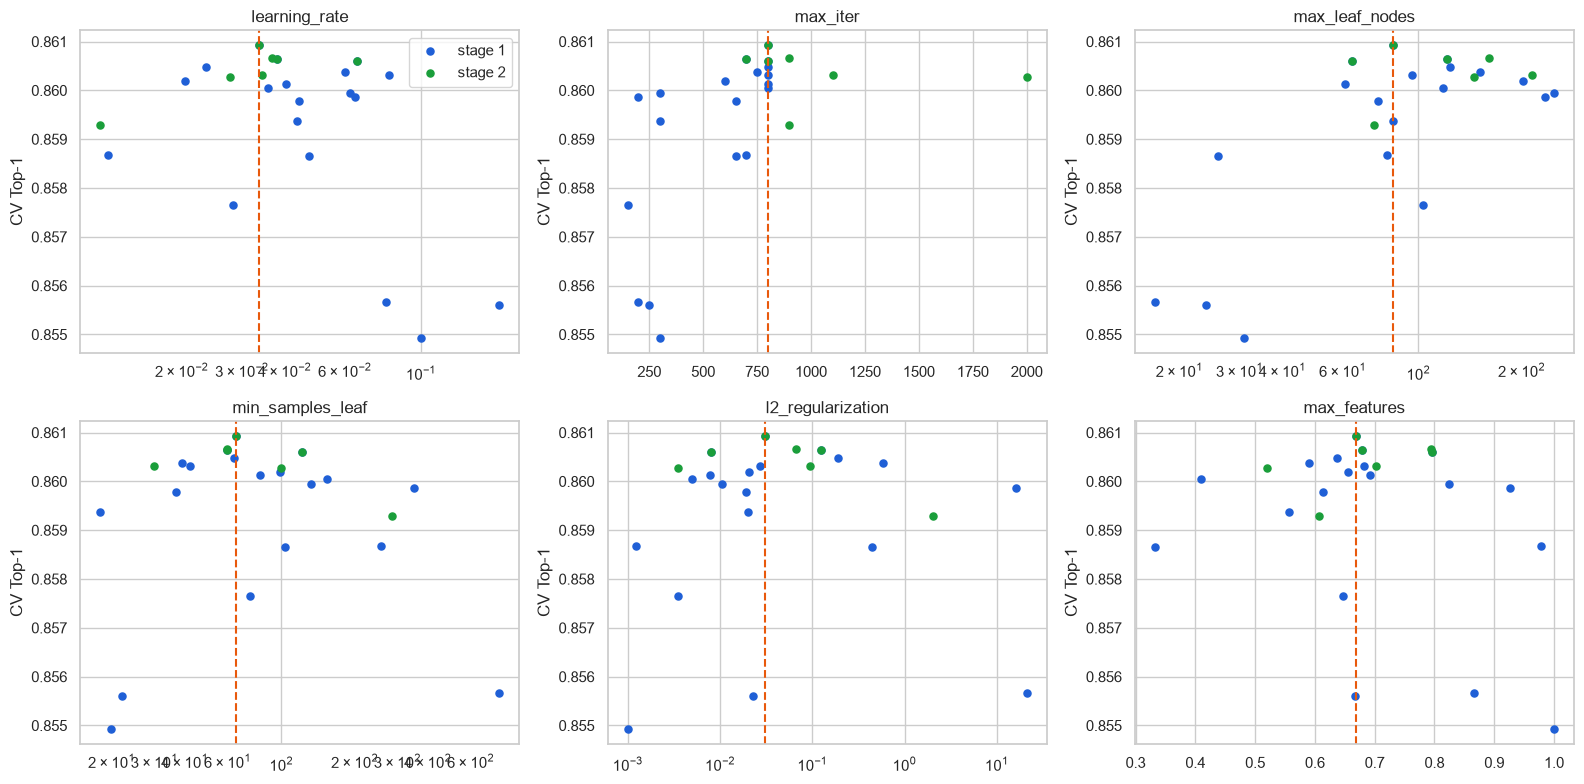

In [4]:
params = list(res['best_params'])
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, p in zip(axes.ravel(), params):
    for st, c in [(1, '#1f5fd6'), (2, '#1a9e3a')]:
        d = done[done.stage == st]; ax.scatter(d[p], d.cv_top1, s=26, c=c, label=f'stage {st}')
    ax.axvline(res['best_params'][p], c='#e8590c', ls='--')
    if p in ('learning_rate', 'l2_regularization', 'min_samples_leaf', 'max_leaf_nodes'): ax.set_xscale('log')
    ax.set_title(p); ax.set_ylabel('CV Top-1')
axes[0, 0].legend()
savefig('02_slices')

Stage 1 found the optimum at `max_iter = 800`, the upper bound. Stage 2 therefore allowed up to 2000 rounds. Configurations with more
rounds were not better: they reached similar Top-1 with **higher log loss** (mild overfitting). So the stage-1 optimum is a genuine
peak, not an artefact of the range limit.

## 2. Untuned vs tuned under the same protocol

The tuned configuration is re-run through the **same 5 GroupKFold folds** with the full metric set used for the untuned model in
stage 4 (the search itself only recorded Top-1 and log loss). Both models are refit on all fitting data and scored once on student_test.

In [5]:
train, train_eval = load_train()
X, y = train[FEATURES].to_numpy(np.float32), train.y.to_numpy()
part = {t: 'train' for t in train.trip.unique()}
rows = []
for k, (a, b) in enumerate(GroupKFold(n_splits=N_FOLDS).split(train, y, train.trip)):
    t0 = time.time(); m = make_model(res['best_params']).fit(X[a], y[a]); ft = time.time() - t0
    val = train_eval[train_eval.trip.isin(train.trip.iloc[b].unique())]
    rows.append(dict(fold=k, train_time_s=ft, **all_metrics(val, m.predict_proba(val[FEATURES].to_numpy(np.float32))[:, 1], part)))
cv_tuned = pd.DataFrame(rows); cv_tuned.to_csv(f'{TUN}/tuned_cv.csv', index=False)
cv_untuned = pd.read_csv(f'{CMP}/HistGradientBoosting_cv.csv')
untuned = json.load(open(f'{CMP}/HistGradientBoosting.json'))
def col(cv, r, tt):
    return {'CV Macro F1': cv.macro_f1.mean(), 'CV Top-1': cv.top1_accuracy.mean(), 'CV log loss': cv.log_loss.mean(),
            'CV route continuity': cv.route_continuity.mean(),
            'Student-test Top-1': r['test']['top1_accuracy'], 'Student-test Macro F1': r['test']['macro_f1'],
            'Student-test precision': r['test']['precision'], 'Student-test recall': r['test']['recall'],
            'Student-test log loss': r['test']['log_loss'], 'Student-test route continuity': r['test']['route_continuity'],
            'Train time (s, full fit)': tt, 'Inference (ms / 1k rows)': r['inference_ms_per_1k_rows']}
cmp = pd.DataFrame({'untuned': col(cv_untuned, untuned, untuned['train_time_s']), 'tuned': col(cv_tuned, res, res['refit_seconds'])})
cmp['change'] = cmp.tuned - cmp.untuned
cmp.to_csv(f'{TUN}/untuned_vs_tuned.csv'); cmp.round(4)

,untuned,tuned,change
CV Macro F1,0.9148,0.9178,0.0030
CV Top-1,0.8540,0.8597,0.0057
CV log loss,0.1042,0.0973,-0.0069
CV route continuity,0.9606,0.9675,0.0070
Student-test Top-1,0.8722,0.8814,0.0092
Student-test Macro F1,0.9247,0.9290,0.0043
Student-test precision,0.8808,0.8958,0.0150
Student-test recall,0.8570,0.8571,0.0001
Student-test log loss,0.0875,0.0772,-0.0103
Student-test route continuity,0.9599,0.9685,0.0085


tuned better on 5 of 5 folds; mean gain +0.0057


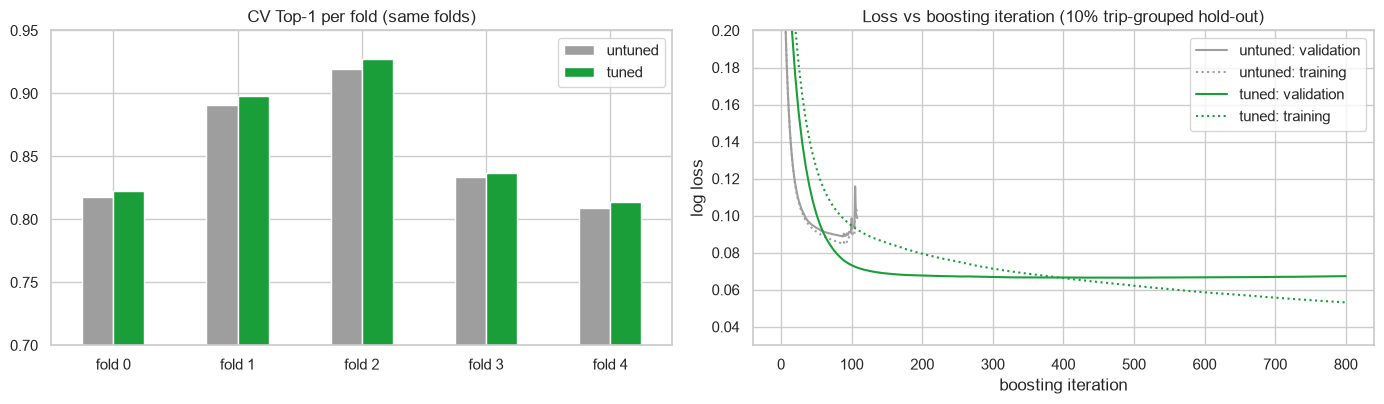

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
d = pd.DataFrame({'untuned': cv_untuned.top1_accuracy.values, 'tuned': cv_tuned.top1_accuracy.values}, index=[f'fold {i}' for i in range(N_FOLDS)])
d.plot.bar(ax=ax[0], rot=0, color=['#9e9e9e', '#1a9e3a']); ax[0].set_ylim(0.7, 0.95); ax[0].set_title('CV Top-1 per fold (same folds)')
print('tuned better on', int((d.tuned > d.untuned).sum()), 'of', N_FOLDS, 'folds; mean gain', f'{(d.tuned - d.untuned).mean():+.4f}')
hu = pd.DataFrame(untuned['history']); ht = pd.DataFrame(res['history'])
ax[1].plot(hu.iteration, hu.val_loss, c='#9e9e9e', label='untuned: validation'); ax[1].plot(hu.iteration, hu.train_loss, c='#9e9e9e', ls=':', label='untuned: training')
ax[1].plot(ht.iteration, ht.val_loss, c='#1a9e3a', label='tuned: validation'); ax[1].plot(ht.iteration, ht.train_loss, c='#1a9e3a', ls=':', label='tuned: training')
ax[1].set_ylim(0.03, 0.2); ax[1].set_xlabel('boosting iteration'); ax[1].set_ylabel('log loss'); ax[1].legend()
ax[1].set_title('Loss vs boosting iteration (10% trip-grouped hold-out)')
savefig('03_untuned_vs_tuned')

The untuned model's validation loss is lowest at iteration 88 and jumps near iteration 105 (learning rate 0.1, no L2), and sklearn's
early stopping keeps the trees after the best iteration. The tuned configuration (learning rate 0.034, L2 0.03, 67% feature subsampling, min 65 samples per leaf) decreases
smoothly (no rise larger than 0.0001 between checkpoints) and flattens after about 500 of its 800 iterations. This is the instability that tuning was expected to fix (notebook 03).

## 3. Comparison search: LightGBM

LightGBM was added to the model comparison after HistGradientBoosting had been selected. It was the best *untuned* model, so it received
the same Bayesian treatment (`scripts/tune_lgbm.py`, same folds and objective; boosting rounds chosen by early stopping). The search was
stopped after 16 completed trials because its CV Top-1 stayed in a narrow band below tuned HistGradientBoosting (best 0.8597 vs 0.8609). Both searches ran before the
candidate tie-break fix; the HGB numbers in sections 1–2 that are recomputed in this notebook use the fixed features.

In [7]:
sl = optuna.load_study(study_name='lgbm_top1', storage='sqlite:///../outputs/models/tuning_lgbm/optuna.db')
lc = [t for t in sl.trials if t.state.name == 'COMPLETE']
lu = [t.value for t in sl.trials if t.number == 0][0]
summary = pd.DataFrame({
    'HistGradientBoosting': {'trials (all states)': len(s1.trials) + len(s2.trials), 'CV Top-1 untuned': done.cv_top1.iloc[0],
                             'CV Top-1 best tuned': res['best_cv_top1'], 'CV log loss (best)': res['best_cv_log_loss'],
                             'extra system dependency': 'none (scikit-learn)'},
    'LightGBM': {'trials (all states)': len(sl.trials), 'CV Top-1 untuned': lu, 'CV Top-1 best tuned': sl.best_value,
                 'CV log loss (best)': sl.best_trial.user_attrs['cv_log_loss'], 'extra system dependency': 'libomp (OpenMP runtime)'}})
print('LightGBM trials by state:', dict(Counter(t.state.name for t in sl.trials)))
summary

LightGBM trials by state: {'COMPLETE': 16, 'FAIL': 2, 'PRUNED': 1}


,HistGradientBoosting,LightGBM
trials (all states),49,19
CV Top-1 untuned,0.854928,0.858556
CV Top-1 best tuned,0.860927,0.859747
CV log loss (best),0.096839,0.096479
extra system dependency,none (scikit-learn),libomp (OpenMP runtime)


**Final choice: tuned HistGradientBoosting.** During the search it had the highest cross-validated Top-1 after equal Bayesian treatment;
re-scored on the tie-fixed features it reaches 0.8597, level with the best LightGBM trial. It needs no extra
system library on the API laptop, and LightGBM needed `libomp` installed before it would import. The CV gap between the two is small
compared with the fold-to-fold spread, so the choice rests on the selection metric plus deployment simplicity. Student-test results were
**not** used to make it.